# Muon variants WITH post-orthogonalization steps (Muon+ renorm + NorMuon): loss vs wall-clock, bpb vs steps / LR, time-to-target (all depths)

Parses the nanochat training logs from the `sweep_*` runs (`logs/slurm/sweep/sweep_d*.out`). In these runs **both post-orthogonalization steps are ON** (Muon+ Frobenius renormalization and NorMuon variance reduction, the nanochat defaults); only MuonEq / Muon$^2$ vary. Every figure carries this in its title, and every saved table has a `config` column and a `postorth` file-name tag, so these results can't be confused with the `plain_*` sweep where both are off. Depths with no finished runs yet are skipped, so this can be re-run as the sweep progresses.

- **Wall-clock** = nanochat's own `total time` counter: pure training step time, excluding the first 10 steps, evals and compile/startup.
- **Wall-clock / steps plots**: per depth, each variant at its best LR (lowest final val bpb among finished runs). Set `LR_MODE` to a number to pin one LR instead.
- **bpb vs LR plot**: final val bpb against `--matrix-lr`, one line per variant, one panel per depth.
- **Time-to-target table**: target = the worst final value among the compared variants (per depth); steps and wall-clock to first reach it, plus speedup.
- **Outputs**: every figure is saved (PNG + PDF) to `<repo>/results/figures/` and every table (CSV) to `<repo>/results/tables/`, with names starting `sweep_postorth_`.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DEPTHS = [8, 12, 16]
TAG_PREFIX = "sweep"    # run-tag prefix set in sweep.sbatch (logs are <prefix>_d<depth>_<variant>_lr<lr>-<jobid>.out)
OUT_PREFIX = f"{TAG_PREFIX}_postorth"   # prefix of every saved figure / table file
CONFIG_NOTE = "post-orthogonalization steps ON: Muon+ renorm + NorMuon variance reduction"
LR_MODE = "best"        # "best" = best final val bpb per (depth, variant); or a number like 0.02 to pin one LR for all
SHOW_ALL_LRS = False    # in the wall-clock plots, also draw the non-selected LRs as faint lines
LOSS_ZOOM, BPB_ZOOM = 1.0, 0.25   # y-range above the best final value in the wall-clock plots

LABELS = {
    "eq":    "MuonEq (nanochat default)",
    "eq_m2": "MuonEq + Muon$^2$",
    "m2":    "Muon$^2$",
    "base":  "Muon (no EQ, no Muon$^2$)",
}
COLORS = {"eq": "tab:blue", "eq_m2": "tab:red", "m2": "tab:green", "base": "tab:gray"}

# --- output directories: <repo root>/results/{figures,tables}; the notebook lives in <repo root>/notebooks/
def find_repo_root():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / ".git").exists():
            return p
    return cwd.parent if cwd.name == "notebooks" else cwd

ROOT = find_repo_root()
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
print("repo root:", ROOT)

def finish_fig(fig, name):
    """Stamp the post-orthogonalization config on the figure, then save it as PNG + PDF in results/figures."""
    fig.suptitle(CONFIG_NOTE, fontsize=9, color="dimgray")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{OUT_PREFIX}_{name}.{ext}", dpi=200, bbox_inches="tight")

def savetable(df, name, index=True):
    """Save a table as CSV in results/tables (tables without an index get a `config` column)."""
    if not index:
        df = df.assign(config=CONFIG_NOTE)
    df.to_csv(TAB_DIR / f"{OUT_PREFIX}_{name}.csv", index=index)

repo root: /home/simon/work/courses/dsa4k/optimizer-comparison


In [2]:
FILE_RE  = re.compile(rf"{re.escape(TAG_PREFIX)}_d(\d+)_(eq_m2|eq|m2|base)_lr([0-9.eE+-]+?)-(\d+)\.out$")
STEP_RE  = re.compile(r"^step (\d+)/(\d+) .*?\| loss: ([0-9.]+) .*?\| dt: ([0-9.]+)ms .*?total time: ([0-9.]+)m", re.M)
VAL_RE   = re.compile(r"^Step (\d+) \| Validation bpb: ([0-9.]+)", re.M)

# Find every logs/slurm/sweep dir at or above the cwd (the scripts may have been launched from a subdir like jobs/)
log_dirs = [p / "logs" / "slurm" / "sweep" for p in [Path.cwd(), *Path.cwd().parents]]
log_dirs = [d for d in log_dirs if d.is_dir()]
print("log dirs:", [str(d) for d in log_dirs])

runs = {}   # (depth, variant, lr) -> dict; if a tag has several logs keep the one with the most steps
for d in log_dirs:
    for path in d.glob("*.out"):
        m = FILE_RE.search(path.name)
        if not m or int(m.group(1)) not in DEPTHS:
            continue
        text = path.read_text(errors="replace")
        steps = STEP_RE.findall(text)
        if not steps:
            continue
        train = pd.DataFrame(steps, columns=["step", "n_iters", "loss", "dt_ms", "time_min"]).astype(float)
        val = pd.DataFrame(VAL_RE.findall(text), columns=["step", "val_bpb"]).astype(float)
        # wall-clock (training time only) at each eval step; the last eval comes after the final train step
        val["time_min"] = np.interp(val["step"], train["step"], train["time_min"])
        n_iters = int(train["n_iters"].iloc[0])
        mb = re.search(r"[Tt]otal batch size[^0-9]*([\d,]+)", text)   # tokens per optimizer step (NaN if the log line isn't found)
        batch_tokens = int(mb.group(1).replace(",", "")) if mb else np.nan
        key = (int(m.group(1)), m.group(2), float(m.group(3)))
        if key not in runs or len(train) > len(runs[key]["train"]):
            runs[key] = dict(train=train, val=val, path=path, n_iters=n_iters, batch_tokens=batch_tokens,
                             finished=len(train) >= n_iters and len(val) > 0)

rows = []
for (depth, v, lr), r in sorted(runs.items()):
    rows.append(dict(depth=depth, variant=v, lr=lr, finished=r["finished"],
                     final_val_bpb=r["val"]["val_bpb"].iloc[-1] if len(r["val"]) else np.nan,
                     final_train_loss=r["train"]["loss"].iloc[-1],
                     train_min=r["train"]["time_min"].iloc[-1],
                     median_ms_per_step=r["train"]["dt_ms"].iloc[10:].median()))
summary = pd.DataFrame(rows)
if len(summary):
    savetable(summary, "all_runs_summary", index=False)
avail = [int(d) for d in sorted(summary[summary.finished].depth.unique())] if len(summary) else []
print("depths with finished runs:", avail)
print("finished runs per depth:", summary[summary.finished].groupby("depth").size().to_dict() if len(summary) else {})
summary

log dirs: ['/home/simon/work/courses/dsa4k/optimizer-comparison/logs/slurm/sweep']
depths with finished runs: [8, 12, 16]
finished runs per depth: {8: 20, 12: 20, 16: 20}


,depth,variant,lr,finished,final_val_bpb,final_train_loss,train_min,median_ms_per_step
0,8,base,0.005,True,0.966126,3.179370,14.42,451.250
1,8,base,0.010,True,0.946256,3.113984,15.51,488.115
2,8,base,0.020,True,0.943899,3.106512,15.51,487.860
3,8,base,0.040,True,0.947393,3.118509,15.52,488.140
4,8,base,0.080,True,0.955785,3.146774,18.13,570.670
5,8,eq,0.005,True,0.957609,3.151327,14.30,450.080
6,8,eq,0.010,True,0.947484,3.118314,14.90,452.760
7,8,eq,0.020,True,0.944423,3.109243,16.74,637.055
8,8,eq,0.040,True,0.946718,3.116381,13.09,372.275
9,8,eq,0.080,True,0.957848,3.154249,14.78,485.915


In [3]:
# Pick one LR per (depth, variant)
chosen = {}
for depth in avail:
    for v in LABELS:
        s = summary[(summary.depth == depth) & (summary.variant == v) & summary.finished]
        if s.empty:
            print(f"d{depth}: no finished runs for {v}"); continue
        if LR_MODE == "best":
            chosen[(depth, v)] = s.loc[s.final_val_bpb.idxmin(), "lr"]
        elif float(LR_MODE) in set(s.lr):
            chosen[(depth, v)] = float(LR_MODE)
        else:
            print(f"d{depth}: {v} has no finished run at lr={LR_MODE}")

sel = summary[summary.apply(lambda r: chosen.get((r.depth, r.variant)) == r.lr, axis=1)]
sel_table = sel.set_index(["depth", "variant"]).sort_index()
if len(sel_table):
    savetable(sel_table, "selected_runs")
sel_table

lr  finished  final_val_bpb  final_train_loss  train_min  \
depth variant                                                               
8     base     0.02      True       0.943899          3.106512      15.51   
      eq       0.02      True       0.944423          3.109243      16.74   
      eq_m2    0.02      True       0.946092          3.114883      15.53   
      m2       0.02      True       0.947244          3.118749      10.52   
12    base     0.02      True       0.848447          2.813136      81.73   
      eq       0.02      True       0.847100          2.808979      89.47   
      eq_m2    0.02      True       0.848110          2.811612      94.67   
      m2       0.02      True       0.847765          2.811447      94.92   
16    base     0.02      True       0.782752          2.565330     237.01   
      eq       0.02      True       0.782616          2.565369     220.64   
      eq_m2    0.02      True       0.783898          2.568817     226.18   
      m2       0.02      True       0.783454          2.568270     225.77   

               median_ms_per_step  
depth variant                      
8     base                487.860  
      eq                  637.055  
      eq_m2               488.190  
      m2                  328.050  
12    base               1975.715  
      eq                 2329.560  
      eq_m2              2363.320  
      m2                 2357.010  
16    base               2643.420  
      eq                 2460.955  
      eq_m2              2525.220  
      m2                 2523.900

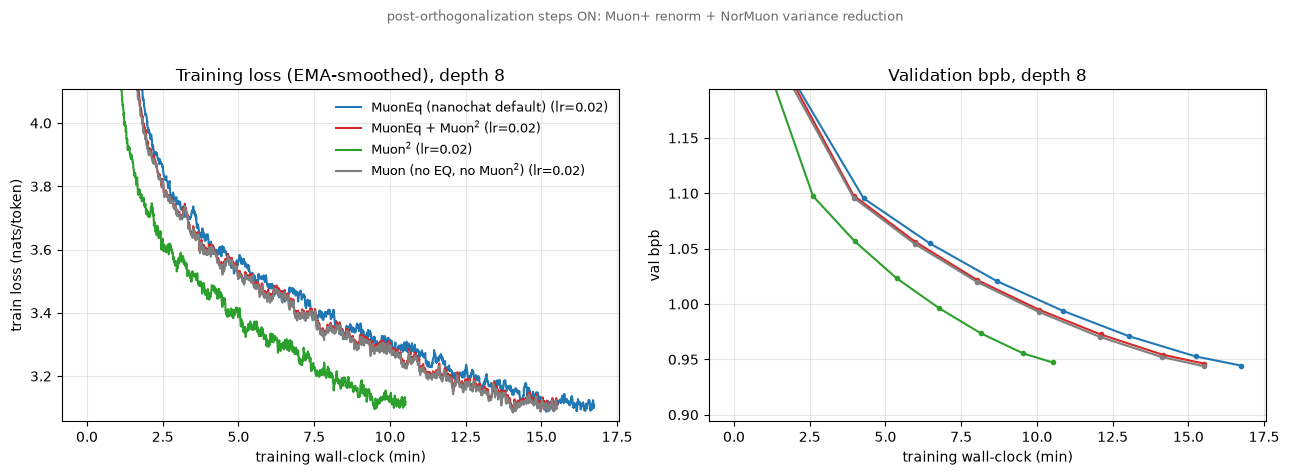

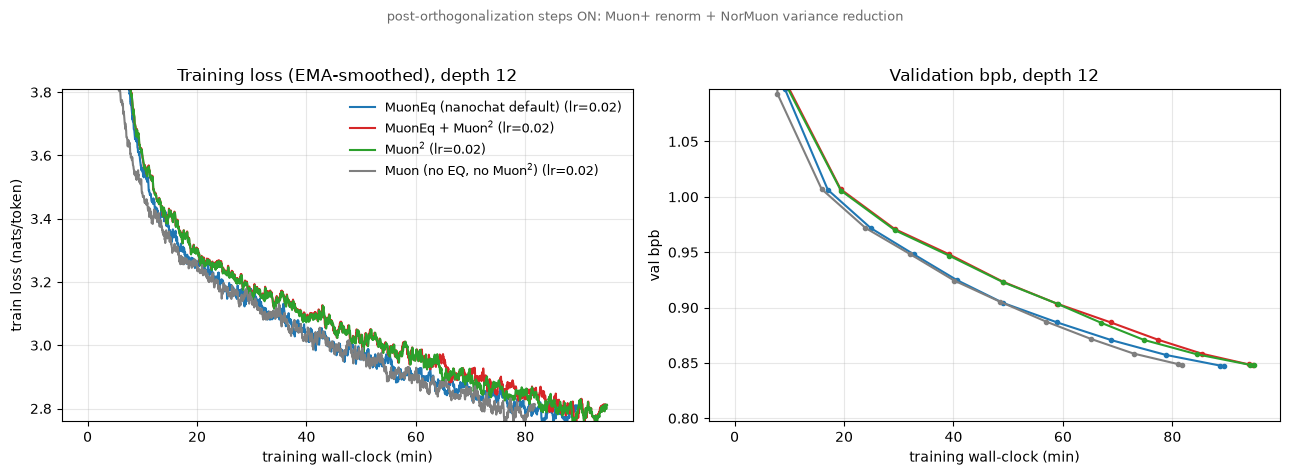

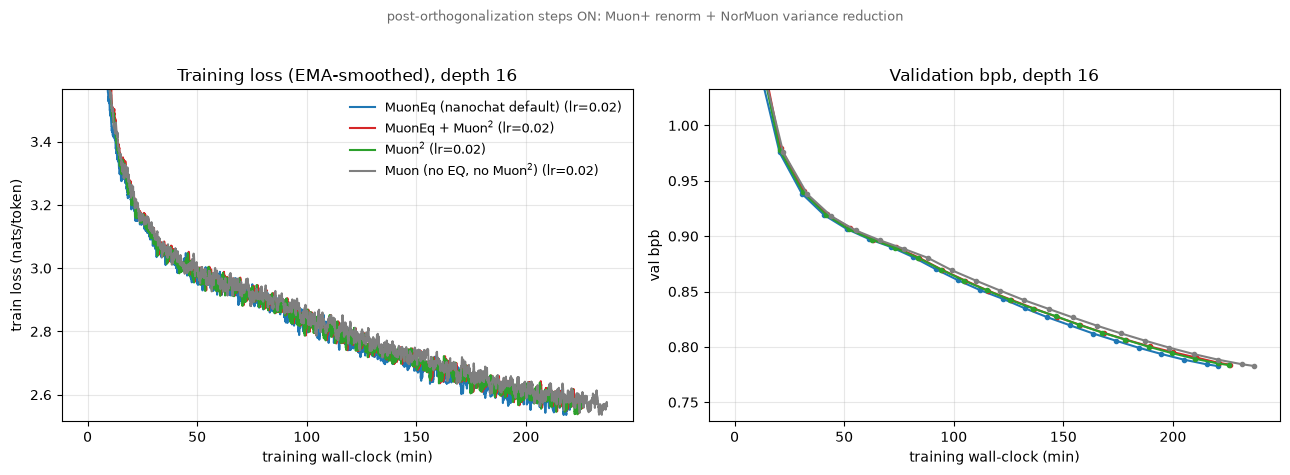

In [4]:
def plot_wallclock(depth):
    vs = [v for v in LABELS if (depth, v) in chosen]
    if not vs:
        return
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for v in vs:
        lr = chosen[(depth, v)]
        r = runs[(depth, v, lr)]
        label = f"{LABELS[v]} (lr={lr:g})"
        axes[0].plot(r["train"]["time_min"], r["train"]["loss"], color=COLORS[v], lw=1.5, label=label)
        axes[1].plot(r["val"]["time_min"], r["val"]["val_bpb"], color=COLORS[v], lw=1.5, marker="o", ms=3, label=label)
        if SHOW_ALL_LRS:
            for (d2, v2, lr2), r2 in runs.items():
                if d2 == depth and v2 == v and lr2 != lr and r2["finished"]:
                    axes[0].plot(r2["train"]["time_min"], r2["train"]["loss"], color=COLORS[v], lw=0.6, alpha=0.25)
                    axes[1].plot(r2["val"]["time_min"], r2["val"]["val_bpb"], color=COLORS[v], lw=0.6, alpha=0.25)

    # zoom the y-axes onto the interesting part (drop the initial high-loss transient)
    fl = min(runs[(depth, v, chosen[(depth, v)])]["train"]["loss"].iloc[-1] for v in vs)
    fb = min(runs[(depth, v, chosen[(depth, v)])]["val"]["val_bpb"].iloc[-1] for v in vs)
    axes[0].set_ylim(fl - 0.05, fl + LOSS_ZOOM)
    axes[1].set_ylim(fb - 0.05, fb + BPB_ZOOM)

    axes[0].set_title(f"Training loss (EMA-smoothed), depth {depth}")
    axes[0].set_ylabel("train loss (nats/token)")
    axes[1].set_title(f"Validation bpb, depth {depth}")
    axes[1].set_ylabel("val bpb")
    for ax in axes:
        ax.set_xlabel("training wall-clock (min)")
        ax.grid(alpha=0.3)
    axes[0].legend(frameon=False, fontsize=9)
    finish_fig(fig, f"d{depth}_loss_val_vs_wallclock")
    plt.show()

for depth in avail:
    plot_wallclock(depth)

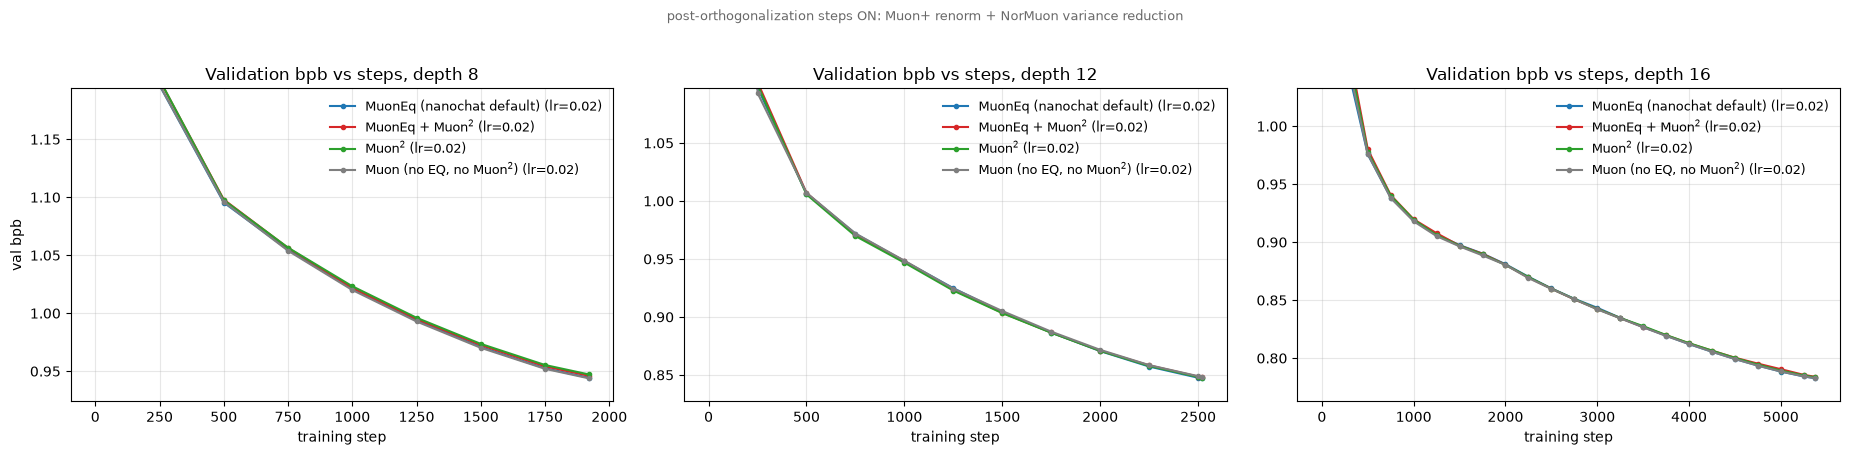

In [5]:
# Validation bpb vs training steps, one panel per depth (each variant at its chosen LR)
if avail:
    fig, axes = plt.subplots(1, len(avail), figsize=(6.2 * len(avail), 4.6), squeeze=False)
    for ax, depth in zip(axes[0], avail):
        vs = [v for v in LABELS if (depth, v) in chosen]
        for v in vs:
            lr = chosen[(depth, v)]
            val = runs[(depth, v, lr)]["val"]
            ax.plot(val["step"], val["val_bpb"], color=COLORS[v], lw=1.5, marker="o", ms=3, label=f"{LABELS[v]} (lr={lr:g})")
        if vs:
            fb = min(runs[(depth, v, chosen[(depth, v)])]["val"]["val_bpb"].iloc[-1] for v in vs)
            ax.set_ylim(fb - 0.02, fb + BPB_ZOOM)
        ax.set_title(f"Validation bpb vs steps, depth {depth}")
        ax.set_xlabel("training step")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=9)
    axes[0][0].set_ylabel("val bpb")
    finish_fig(fig, "val_bpb_vs_steps")
    plt.show()

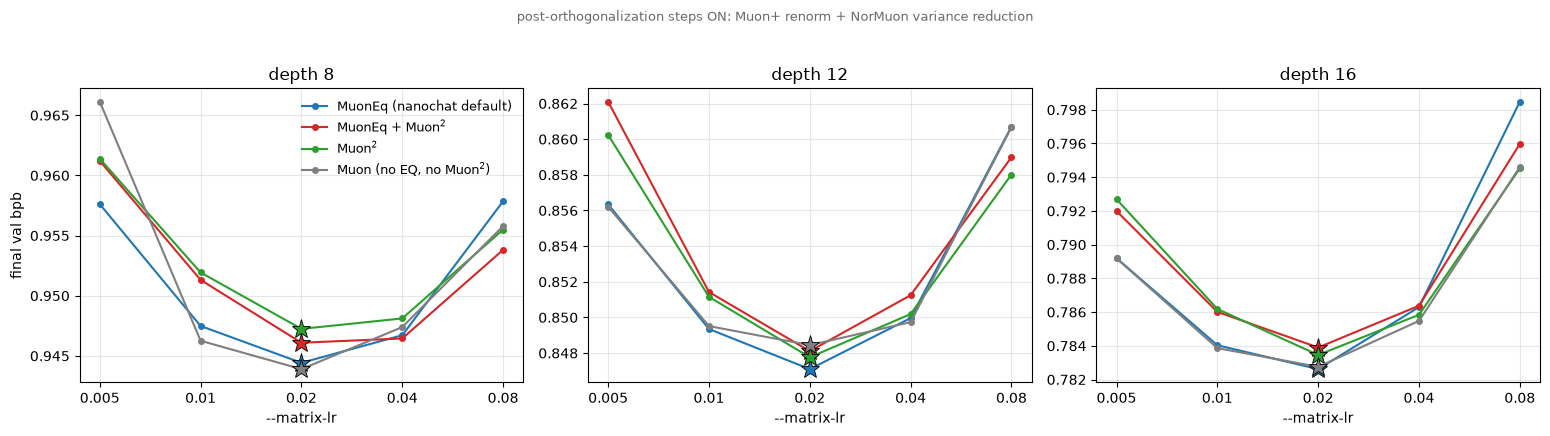

lr              0.005   0.010   0.020   0.040   0.080
depth variant                                        
8     base     0.9661  0.9463  0.9439  0.9474  0.9558
      eq       0.9576  0.9475  0.9444  0.9467  0.9578
      eq_m2    0.9612  0.9513  0.9461  0.9464  0.9538
      m2       0.9614  0.9519  0.9472  0.9481  0.9555
12    base     0.8562  0.8495  0.8484  0.8497  0.8607
      eq       0.8563  0.8493  0.8471  0.8500  0.8607
      eq_m2    0.8621  0.8514  0.8481  0.8512  0.8590
      m2       0.8602  0.8512  0.8478  0.8502  0.8580
16    base     0.7892  0.7839  0.7828  0.7855  0.7946
      eq       0.7892  0.7840  0.7826  0.7863  0.7985
      eq_m2    0.7920  0.7860  0.7839  0.7864  0.7960
      m2       0.7927  0.7862  0.7835  0.7858  0.7945

In [6]:
# Final val bpb vs matrix LR, one panel per depth (star = best LR for that variant)
fin = summary[summary.finished]
if fin.empty:
    print("no finished runs yet")
else:
    fig, axes = plt.subplots(1, len(avail), figsize=(5.2 * len(avail), 4.4), squeeze=False)
    for ax, depth in zip(axes[0], avail):
        for v in LABELS:
            s = fin[(fin.depth == depth) & (fin.variant == v)].sort_values("lr")
            if s.empty:
                continue
            ax.plot(s.lr, s.final_val_bpb, color=COLORS[v], marker="o", ms=4, lw=1.5, label=LABELS[v])
            b = s.loc[s.final_val_bpb.idxmin()]
            ax.plot([b.lr], [b.final_val_bpb], color=COLORS[v], marker="*", ms=14, mec="k", mew=0.6)
        lrs = sorted(fin[fin.depth == depth].lr.unique())
        ax.set_xscale("log")
        ax.set_xticks(lrs)
        ax.set_xticklabels([f"{x:g}" for x in lrs])
        ax.minorticks_off()
        ax.set_title(f"depth {depth}")
        ax.set_xlabel("--matrix-lr")
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("final val bpb")
    axes[0][0].legend(frameon=False, fontsize=9)
    finish_fig(fig, "val_bpb_vs_lr")
    plt.show()

    # compact table of the same numbers: rows = (depth, variant), columns = LR
    lr_pivot = fin.pivot_table(index=["depth", "variant"], columns="lr", values="final_val_bpb").round(4)
    savetable(lr_pivot, "val_bpb_vs_lr")
    display(lr_pivot)

## Time-to-target

For each depth, the **target is a constant: the worst (highest) final value among the compared variants**, each at its selected LR, so every variant reaches it by the end of its run. We report the first step and wall-clock minute at which each variant reaches the target (linear interpolation between logged points; validation bpb is only logged every `--eval-every` steps, the smoothed train loss every step).

**Speedup** follows the Muon+ paper convention: `T_ref / T_variant - 1`, in %, separately for steps and wall-clock, with `REFERENCE` as the baseline (falls back to the worst variant if `REFERENCE` isn't available at that depth). Positive = faster than the reference. Tokens = steps × the total batch size parsed from the log (NaN if that line isn't found; batch size is identical across variants within a depth). All numbers are for runs with the post-orthogonalization steps (Muon+ renorm + NorMuon) ON.

In [7]:
REFERENCE = "base"   # baseline for the speedup column
TARGET_METRICS = {"val_bpb": "val bpb", "loss": "train loss (EMA)"}

def metric_series(r, metric):
    d = r["val"] if metric == "val_bpb" else r["train"]
    return d["step"].to_numpy(), d["time_min"].to_numpy(), d[metric].to_numpy()

def first_crossing(steps, times, y, target):
    """First (step, minute) at which y <= target, linearly interpolated; NaN if never reached."""
    idx = np.flatnonzero(y <= target)
    if len(idx) == 0:
        return np.nan, np.nan
    i = idx[0]
    if i == 0:
        return steps[0], times[0]
    f = (y[i - 1] - target) / (y[i - 1] - y[i])
    return steps[i - 1] + f * (steps[i] - steps[i - 1]), times[i - 1] + f * (times[i] - times[i - 1])

rows = []
for depth in avail:
    vs = [v for v in LABELS if (depth, v) in chosen]
    if len(vs) < 2:
        continue
    for metric, mname in TARGET_METRICS.items():
        finals = {v: metric_series(runs[(depth, v, chosen[(depth, v)])], metric)[2][-1] for v in vs}
        worst = max(finals, key=finals.get)
        target = finals[worst]
        res = {}
        for v in vs:
            r = runs[(depth, v, chosen[(depth, v)])]
            st, tm = first_crossing(*metric_series(r, metric), target)
            res[v] = dict(steps=st, minutes=tm, tokens_M=st * r["batch_tokens"] / 1e6)
        ref = REFERENCE if REFERENCE in res else worst
        for v in vs:
            rows.append(dict(
                depth=depth, metric=mname, target=target, target_set_by=worst, reference=ref,
                variant=v, lr=chosen[(depth, v)], final=finals[v],
                steps_to_target=res[v]["steps"], tokens_M=res[v]["tokens_M"], minutes_to_target=res[v]["minutes"],
                speedup_steps_pct=(res[ref]["steps"] / res[v]["steps"] - 1) * 100,
                speedup_time_pct=(res[ref]["minutes"] / res[v]["minutes"] - 1) * 100,
            ))

ttt = pd.DataFrame(rows)
if ttt.empty:
    print("need at least two finished variants at a depth")
else:
    ttt = ttt.round({"target": 4, "final": 4, "steps_to_target": 0, "tokens_M": 1, "minutes_to_target": 2,
                     "speedup_steps_pct": 1, "speedup_time_pct": 1})
    savetable(ttt, "time_to_target", index=False)
    print(CONFIG_NOTE)
    display(ttt.set_index(["depth", "metric", "variant"]))

post-orthogonalization steps ON: Muon+ renorm + NorMuon variance reduction


target target_set_by reference    lr   final  \
depth metric           variant                                                 
8     val bpb          eq       0.9472            m2      base  0.02  0.9444   
                       eq_m2    0.9472            m2      base  0.02  0.9461   
                       m2       0.9472            m2      base  0.02  0.9472   
                       base     0.9472            m2      base  0.02  0.9439   
      train loss (EMA) eq       3.1187            m2      base  0.02  3.1092   
                       eq_m2    3.1187            m2      base  0.02  3.1149   
                       m2       3.1187            m2      base  0.02  3.1187   
                       base     3.1187            m2      base  0.02  3.1065   
12    val bpb          eq       0.8484          base      base  0.02  0.8471   
                       eq_m2    0.8484          base      base  0.02  0.8481   
                       m2       0.8484          base      base  0.02  0.8478   
                       base     0.8484          base      base  0.02  0.8484   
      train loss (EMA) eq       2.8131          base      base  0.02  2.8090   
                       eq_m2    2.8131          base      base  0.02  2.8116   
                       m2       2.8131          base      base  0.02  2.8114   
                       base     2.8131          base      base  0.02  2.8131   
16    val bpb          eq       0.7839         eq_m2      base  0.02  0.7826   
                       eq_m2    0.7839         eq_m2      base  0.02  0.7839   
                       m2       0.7839         eq_m2      base  0.02  0.7835   
                       base     0.7839         eq_m2      base  0.02  0.7828   
      train loss (EMA) eq       2.5688         eq_m2      base  0.02  2.5654   
                       eq_m2    2.5688         eq_m2      base  0.02  2.5688   
                       m2       2.5688         eq_m2      base  0.02  2.5683   
                       base     2.5688         eq_m2      base  0.02  2.5653   

                                steps_to_target  tokens_M  minutes_to_target  \
depth metric           variant                                                 
8     val bpb          eq                1861.0     488.0              16.23   
                       eq_m2             1896.0     497.0              15.33   
                       m2                1920.0     503.3              10.52   
                       base              1850.0     485.1              14.94   
      train loss (EMA) eq                1694.0     444.0              14.75   
                       eq_m2             1694.0     444.0              13.69   
                       m2                1694.0     444.1               9.23   
                       base              1693.0     443.9              13.67   
12    val bpb          eq                2478.0    1299.2              87.85   
                       eq_m2             2507.0    1314.3              94.23   
                       m2                2495.0    1308.1              93.99   
                       base              2520.0    1321.2              81.73   
      train loss (EMA) eq                2197.0    1152.1              76.72   
                       eq_m2             2198.0    1152.2              83.79   
                       m2                2198.0    1152.1              82.45   
                       base              2198.0    1152.3              71.59   
16    val bpb          eq                5275.0    2765.8             216.49   
                       eq_m2             5376.0    2818.6             226.18   
                       m2                5341.0    2800.4             224.32   
                       base              5284.0    2770.5             233.00   
      train loss (EMA) eq                4680.0    2453.9             191.86   
                       eq_m2             4681.0    2454.0             196.96   
                       m2      